In [1]:

!pip -q install pandas numpy scikit-learn matplotlib

In [2]:

from google.colab import files

uploaded = files.upload()


Saving sri_lankan_supermarket_purchase_history.csv to sri_lankan_supermarket_purchase_history.csv


In [3]:

import pandas as pd

df = pd.read_csv("sri_lankan_supermarket_purchase_history.csv")

df["purchase_date"] = pd.to_datetime(df["purchase_date"])

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (15542, 7)


,customer_id,transaction_id,purchase_date,product_id,product_name,category,quantity
0,C0004,T0000046,2025-01-01,P01514,Ariel Bar Soap for Laundry 1000g,Household - Laundry,3
1,C0004,T0000046,2025-01-01,P01587,Sunlight Liquid Detergent 200g,Household - Laundry,1
2,C0004,T0000046,2025-01-01,P00973,Ceyoka Sunflower Oil 5000ml,Cooking Oil & Fats,1
3,C0004,T0000046,2025-01-01,P01534,Comfort Bar Soap for Laundry 1000g,Household - Laundry,3
4,C0004,T0000046,2025-01-01,P01806,Sandalwood Body Wash 200ml,Personal Care - Bath & Soap,1


In [4]:

# Check the dataset structure and quality

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of unique customers:", df["customer_id"].nunique())
print("Number of unique transactions:", df["transaction_id"].nunique())
print("Number of unique products:", df["product_id"].nunique())

print("\nPurchase date range:")
print(df["purchase_date"].min(), "to", df["purchase_date"].max())

print("\nData types:")
print(df.dtypes)


Dataset shape: (15542, 7)

Column names:
['customer_id', 'transaction_id', 'purchase_date', 'product_id', 'product_name', 'category', 'quantity']

Missing values:
customer_id       0
transaction_id    0
purchase_date     0
product_id        0
product_name      0
category          0
quantity          0
dtype: int64

Number of unique customers: 200
Number of unique transactions: 3427
Number of unique products: 2015

Purchase date range:
2025-01-01 00:00:00 to 2025-12-31 00:00:00

Data types:
customer_id               object
transaction_id            object
purchase_date     datetime64[ns]
product_id                object
product_name              object
category                  object
quantity                   int64
dtype: object


In [5]:

# Identify products that customers purchase most often

popular_products = (
    df.groupby(["product_id", "product_name", "category"])
      .agg(
          purchase_count=("transaction_id", "nunique"),
          total_quantity=("quantity", "sum"),
          customer_count=("customer_id", "nunique")
      )
      .sort_values("purchase_count", ascending=False)
      .reset_index()
)

display(popular_products.head(10))


,product_id,product_name,category,purchase_count,total_quantity,customer_count
0,P01406,Prima Rice Flour 1000g,Flour & Baking,43,70,5
1,P00762,Kpo Canned Chickpeas 200g,Canned & Preserved Food,41,59,6
2,P01147,Kotmale Sterilized Milk 180ml,Dairy - Liquid & Yogurt,41,78,6
3,P01768,Palmolive Body Wash 75g,Personal Care - Bath & Soap,39,68,4
4,P01204,Richlife UHT Full Cream Milk 400ml,Dairy - Liquid & Yogurt,38,68,7
5,P01875,Pantene Anti-Dandruff Shampoo 340ml,Personal Care - Hair Care,38,77,5
6,P00918,Kandos Eclairs Pack 20g,Chocolate & Confectionery,37,61,8
7,P01197,Richlife Sterilized Milk 180ml,Dairy - Liquid & Yogurt,36,61,6
8,P01413,Prima Wheat Flour 5000g,Flour & Baking,36,56,5
9,P00098,Ovaltine Malt Beverage Powder 200g,Beverages - Malt & Coffee,35,61,7


In [6]:

# Examine one customer's shopping history

customer_id = df["customer_id"].iloc[0]

customer_history = (
    df[df["customer_id"] == customer_id]
    .sort_values("purchase_date")
)

print("Customer ID:", customer_id)
print("Number of purchase records:", len(customer_history))

display(
    customer_history[
        ["purchase_date", "transaction_id",
         "product_name", "category", "quantity"]
    ].tail(15)
)


Customer ID: C0004
Number of purchase records: 57


,purchase_date,transaction_id,product_name,category,quantity
10555,2025-09-04,T0000054,Sandalwood Beauty Soap Bar 100g,Personal Care - Bath & Soap,1
10554,2025-09-04,T0000054,Ceyoka Margarine 1000ml,Cooking Oil & Fats,3
10556,2025-09-04,T0000054,Roshan Baking Powder 1000g,Flour & Baking,1
11040,2025-09-15,T0000055,Fortune Sunflower Oil 750ml,Cooking Oil & Fats,2
11041,2025-09-15,T0000055,Sunlight Liquid Detergent 200g,Household - Laundry,1
11042,2025-09-15,T0000055,Sandalwood Beauty Soap Bar 100g,Personal Care - Bath & Soap,1
11043,2025-09-15,T0000055,Ariel Bar Soap for Laundry 1000g,Household - Laundry,1
11044,2025-09-15,T0000055,Ceyoka Ghee 500ml,Cooking Oil & Fats,1
11045,2025-09-15,T0000055,Comfort Bar Soap for Laundry 1000g,Household - Laundry,3
15496,2025-12-31,T0000056,Ariel Bar Soap for Laundry 1000g,Household - Laundry,1


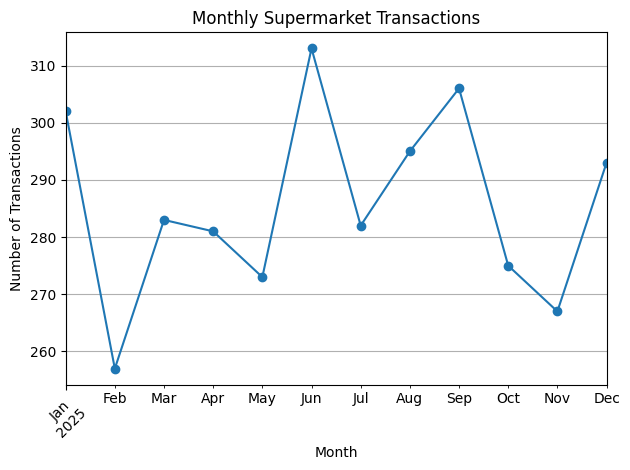

In [7]:

import matplotlib.pyplot as plt

monthly_transactions = (
    df.assign(month=df["purchase_date"].dt.to_period("M"))
      .groupby("month")["transaction_id"]
      .nunique()
)

monthly_transactions.plot(kind="line", marker="o")

plt.title("Monthly Supermarket Transactions")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [8]:

from collections import Counter

df["purchase_date"] = pd.to_datetime(df["purchase_date"])
df = df.sort_values(
    ["customer_id", "purchase_date", "transaction_id"]
).reset_index(drop=True)

feature_rows = []

for customer_id, customer_df in df.groupby("customer_id"):
    transactions = []

    for transaction_id, basket in customer_df.groupby(
        "transaction_id", sort=False
    ):
        transactions.append({
            "transaction_id": transaction_id,
            "date": basket["purchase_date"].min(),
            "items": basket.to_dict("records")
        })

    # We need enough transactions to create history and a target.
    if len(transactions) < 3:
        continue

    split_at = max(1, int((len(transactions) - 1) * 0.8))

    for i in range(len(transactions) - 1):
        history = transactions[:i + 1]
        next_transaction = transactions[i + 1]
        context_date = history[-1]["date"]

        past_rows = []
        for tx in history:
            for item in tx["items"]:
                past_rows.append({
                    **item,
                    "past_date": tx["date"]
                })

        past = pd.DataFrame(past_rows)
        past["days_ago"] = (
            context_date - past["past_date"]
        ).dt.days

        next_products = {
            str(item["product_id"])
            for item in next_transaction["items"]
        }

        stats = past.groupby("product_id").agg(
            product_name=("product_name", "last"),
            category=("category", "last"),
            past_purchase_count=("transaction_id", "nunique"),
            total_quantity=("quantity", "sum"),
            days_since_last_purchase=("days_ago", "min")
        ).reset_index()

        category_counts = past.groupby("category")[
            "transaction_id"
        ].nunique().to_dict()

        for item in stats.to_dict("records"):
            item["category_purchase_count"] = category_counts.get(
                item["category"], 0
            )
            item["label"] = int(
                str(item["product_id"]) in next_products
            )
            item["customer_id"] = customer_id
            item["context_date"] = context_date
            item["split"] = (
                "train" if i < split_at else "test"
            )
            feature_rows.append(item)

model_data = pd.DataFrame(feature_rows)

print("Training examples:",
      (model_data["split"] == "train").sum())
print("Testing examples:",
      (model_data["split"] == "test").sum())

display(model_data.head())


Training examples: 35449
Testing examples: 15398


,product_id,product_name,category,past_purchase_count,total_quantity,days_since_last_purchase,category_purchase_count,label,customer_id,context_date,split
0,P01409,Prima Rice Flour 5000g,Flour & Baking,1,1,0,1,0,C0001,2025-01-04,train
1,P01427,Roshan Rice Flour 2000g,Flour & Baking,1,1,0,1,0,C0001,2025-01-04,train
2,P01857,Head & Shoulders Anti-Dandruff Shampoo 650ml,Personal Care - Hair Care,1,1,0,1,0,C0001,2025-01-04,train
3,P01893,Pantene Shampoo 80ml,Personal Care - Hair Care,1,1,0,1,0,C0001,2025-01-04,train
4,P02191,MD Soy Sauce 340g,Sauces & Condiments,1,1,0,1,1,C0001,2025-01-04,train


In [9]:

from sklearn.ensemble import RandomForestClassifier

# Select the input features
feature_columns = [
    "past_purchase_count",
    "total_quantity",
    "days_since_last_purchase",
    "category_purchase_count"
]

# Separate training and testing data
train_data = model_data[model_data["split"] == "train"].copy()
test_data = model_data[model_data["split"] == "test"].copy()

X_train = train_data[feature_columns].fillna(0)
y_train = train_data["label"]

X_test = test_data[feature_columns].fillna(0)
y_test = test_data["label"]

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest training completed!")
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Training labels:")
print(y_train.value_counts())


Random Forest training completed!
Training examples: 35449
Testing examples: 15398
Training labels:
label
0    27176
1     8273
Name: count, dtype: int64


In [10]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict whether each candidate product appears next
y_pred = model.predict(X_test)

print("Precision:", round(precision_score(
    y_test, y_pred, zero_division=0
), 3))

print("Recall:", round(recall_score(
    y_test, y_pred, zero_division=0
), 3))

print("F1-score:", round(f1_score(
    y_test, y_pred, zero_division=0
), 3))

print("\nDetailed results:")
print(classification_report(
    y_test, y_pred, zero_division=0
))


Precision: 0.393
Recall: 0.638
F1-score: 0.486

Detailed results:
              precision    recall  f1-score   support

           0       0.90      0.77      0.83     12486
           1       0.39      0.64      0.49      2912

    accuracy                           0.74     15398
   macro avg       0.65      0.70      0.66     15398
weighted avg       0.80      0.74      0.77     15398



In [11]:

# Compare Random Forest with a recent-purchase baseline

precision_rf = []
recall_rf = []
precision_recent = []
recall_recent = []

for (customer, context_date), group in test_data.groupby(
    ["customer_id", "context_date"]
):
    actual = set(
        group.loc[group["label"] == 1, "product_id"]
    )

    if not actual:
        continue

    k = min(5, len(group))

    # Random Forest ranking
    rf_top = group.sort_values(
        "score", ascending=False
    ).head(k)

    # Most recently purchased products
    recent_top = group.sort_values(
        "days_since_last_purchase", ascending=True
    ).head(k)

    rf_items = set(rf_top["product_id"])
    recent_items = set(recent_top["product_id"])

    precision_rf.append(len(rf_items & actual) / k)
    recall_rf.append(len(rf_items & actual) / len(actual))

    precision_recent.append(len(recent_items & actual) / k)
    recall_recent.append(len(recent_items & actual) / len(actual))

print("Random Forest Precision@5:",
      round(np.mean(precision_rf), 3))
print("Random Forest Recall@5:",
      round(np.mean(recall_rf), 3))

print("\nRecent-purchase baseline Precision@5:",
      round(np.mean(precision_recent), 3))
print("Recent-purchase baseline Recall@5:",
      round(np.mean(recall_recent), 3))


KeyError: 'score'

In [12]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict whether each candidate product appears next
y_pred = model.predict(X_test)

print("Precision:", round(precision_score(
    y_test, y_pred, zero_division=0
), 3))

print("Recall:", round(recall_score(
    y_test, y_pred, zero_division=0
), 3))

print("F1-score:", round(f1_score(
    y_test, y_pred, zero_division=0
), 3))

print("\nDetailed results:")
print(classification_report(
    y_test, y_pred, zero_division=0
))


Precision: 0.393
Recall: 0.638
F1-score: 0.486

Detailed results:
              precision    recall  f1-score   support

           0       0.90      0.77      0.83     12486
           1       0.39      0.64      0.49      2912

    accuracy                           0.74     15398
   macro avg       0.65      0.70      0.66     15398
weighted avg       0.80      0.74      0.77     15398



In [17]:

# Compare Random Forest with a recent-purchase baseline

precision_rf = []
recall_rf = []
precision_recent = []
recall_recent = []

for (customer, context_date), group in test_data.groupby(
    ["customer_id", "context_date"]
):
    actual = set(
        group.loc[group["label"] == 1, "product_id"]
    )

    if not actual:
        continue

    k = min(5, len(group))

    # Random Forest ranking
    rf_top = group.sort_values(
        "score", ascending=False
    ).head(k)

    # Most recently purchased products
    recent_top = group.sort_values(
        "days_since_last_purchase", ascending=True
    ).head(k)

    rf_items = set(rf_top["product_id"])
    recent_items = set(recent_top["product_id"])

    precision_rf.append(len(rf_items & actual) / k)
    recall_rf.append(len(rf_items & actual) / len(actual))

    precision_recent.append(len(recent_items & actual) / k)
    recall_recent.append(len(recent_items & actual) / len(actual))

print("Random Forest Precision@5:",
      round(np.mean(precision_rf), 3))
print("Random Forest Recall@5:",
      round(np.mean(recall_rf), 3))

print("\nRecent-purchase baseline Precision@5:",
      round(np.mean(precision_recent), 3))
print("Recent-purchase baseline Recall@5:",
      round(np.mean(recall_recent), 3))


Random Forest Precision@5: 0.442
Random Forest Recall@5: 0.559

Recent-purchase baseline Precision@5: 0.341
Recent-purchase baseline Recall@5: 0.423


In [14]:

# Generate Random Forest scores for test candidates

test_data = test_data.copy()

test_data["score"] = model.predict_proba(
    test_data[feature_columns].fillna(0)
)[:, 1]

print("Prediction scores generated successfully!")
display(
    test_data[
        ["customer_id", "product_name", "label", "score"]
    ].head()
)


Prediction scores generated successfully!


,customer_id,product_name,label,score
265,C0001,Elephant House Orange Crush 400ml,0,0.069774
266,C0001,Watawala Earl Grey Tea 25g,0,0.422726
267,C0001,Munchee Milk Toffee Biscuit 400g,0,0.043988
268,C0001,Highland UHT Full Cream Milk 500g,0,0.546964
269,C0001,Richlife Drinking Yogurt 400ml,0,0.485897


In [16]:

import numpy as np
import pandas as pd

print("NumPy and Pandas imported successfully!")


NumPy and Pandas imported successfully!


In [18]:

import numpy as np

# Generate scores if they are not already available
test_data = test_data.copy()

test_data["score"] = model.predict_proba(
    test_data[feature_columns].fillna(0)
)[:, 1]

precision_rf = []
recall_rf = []
precision_recent = []
recall_recent = []

for (customer, context_date), group in test_data.groupby(
    ["customer_id", "context_date"]
):
    actual = set(
        group.loc[group["label"] == 1, "product_id"]
    )

    if not actual:
        continue

    k = min(5, len(group))

    rf_top = group.sort_values(
        "score", ascending=False
    ).head(k)

    recent_top = group.sort_values(
        "days_since_last_purchase", ascending=True
    ).head(k)

    rf_items = set(rf_top["product_id"])
    recent_items = set(recent_top["product_id"])

    precision_rf.append(len(rf_items & actual) / k)
    recall_rf.append(len(rf_items & actual) / len(actual))

    precision_recent.append(len(recent_items & actual) / k)
    recall_recent.append(len(recent_items & actual) / len(actual))

print("RANDOM FOREST")
print("Precision@5:", round(np.mean(precision_rf), 3))
print("Recall@5:", round(np.mean(recall_rf), 3))

print("\nRECENT-PURCHASE BASELINE")
print("Precision@5:", round(np.mean(precision_recent), 3))
print("Recall@5:", round(np.mean(recall_recent), 3))


RANDOM FOREST
Precision@5: 0.442
Recall@5: 0.559

RECENT-PURCHASE BASELINE
Precision@5: 0.341
Recall@5: 0.423


In [19]:

# Display the top five recommendations for a customer

customer_id = test_data["customer_id"].iloc[0]

customer_candidates = test_data[
    test_data["customer_id"] == customer_id
].copy()

latest_date = customer_candidates["context_date"].max()

recommendations = (
    customer_candidates[
        customer_candidates["context_date"] == latest_date
    ]
    .sort_values("score", ascending=False)
    .head(5)
)

print("Customer ID:", customer_id)
print("Recommendation date:", latest_date.date())
print("\nRecommended products:")

display(
    recommendations[
        ["product_name", "category",
         "past_purchase_count",
         "days_since_last_purchase", "score"]
    ].reset_index(drop=True)
)


Customer ID: C0001
Recommendation date: 2025-08-15

Recommended products:


,product_name,category,past_purchase_count,days_since_last_purchase,score
0,Sunsilk Anti-Dandruff Shampoo 340ml,Personal Care - Hair Care,9,0,0.780615
1,Ritzbury Tomato Sauce 750g,Sauces & Condiments,14,0,0.747111
2,Prima Rice Flour 5000g,Flour & Baking,6,21,0.713441
3,MD Soy Sauce 340g,Sauces & Condiments,12,0,0.702105
4,Roshan Rice Flour 2000g,Flour & Baking,5,0,0.672231


In [20]:

print("Random Forest Precision@5:",
      round(np.mean(precision_rf), 3))
print("Random Forest Recall@5:",
      round(np.mean(recall_rf), 3))

print("\nRecent-purchase baseline Precision@5:",
      round(np.mean(precision_recent), 3))
print("Recent-purchase baseline Recall@5:",
      round(np.mean(recall_recent), 3))


Random Forest Precision@5: 0.442
Random Forest Recall@5: 0.559

Recent-purchase baseline Precision@5: 0.341
Recent-purchase baseline Recall@5: 0.423


In [21]:

import joblib

model_package = {
    "model": model,
    "feature_columns": feature_columns
}

joblib.dump(
    model_package,
    "comp4_recommendation_model.joblib"
)

print("Model saved successfully!")


Model saved successfully!


In [22]:

from google.colab import files

files.download("comp4_recommendation_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>